# Telco Customer Churn: who is likely to leave, and who should we call first?

A small end-to-end machine-learning project on the public IBM Telco Customer Churn sample dataset
(7,043 customers, 21 columns).

**Status:** learning project, built in November 2026 while studying *AI for Data Analytics* (Botswana Accountancy College).
It follows the module's workflow (baseline first, cross-validated model comparison, honest evaluation on a held-out test set,
explanation) and was developed with AI assistance. The dataset is a fictional-operator sample, not real customer data.

**Questions**
1. Can we predict which customers will churn better than a naive baseline?
2. Which factors are most associated with churn?
3. If the retention team can only call a fraction of customers, how much does the model help compared with calling at random?

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score, recall_score,
                             ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.inspection import permutation_importance

SEED = 42
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Load and clean the data

In [2]:
df = pd.read_csv("data/telco_customer_churn.csv")
print(df.shape)
# TotalCharges is stored as text; blanks appear for brand-new customers (tenure = 0)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing TotalCharges:", df["TotalCharges"].isna().sum(), "| their tenure values:", df.loc[df.TotalCharges.isna(), "tenure"].unique())
df = df.drop(columns="customerID")
df["Churn"] = (df["Churn"] == "Yes").astype(int)
print("Duplicate rows:", df.duplicated().sum())
print("Churn rate: %.1f%%" % (100*df.Churn.mean()))

(7043, 21)
Missing TotalCharges: 11 | their tenure values: [0]
Duplicate rows: 22
Churn rate: 26.5%


The 11 blank `TotalCharges` values all belong to customers with `tenure = 0` (they have not been billed yet), so they are treated
as missing and imputed inside the modelling pipeline (not before the split, to avoid leakage).
The classes are imbalanced (about 1 in 4 customers churn), so plain accuracy is a poor yardstick: a model that always says
"no churn" would already score about 73%.

## 2. Exploratory analysis

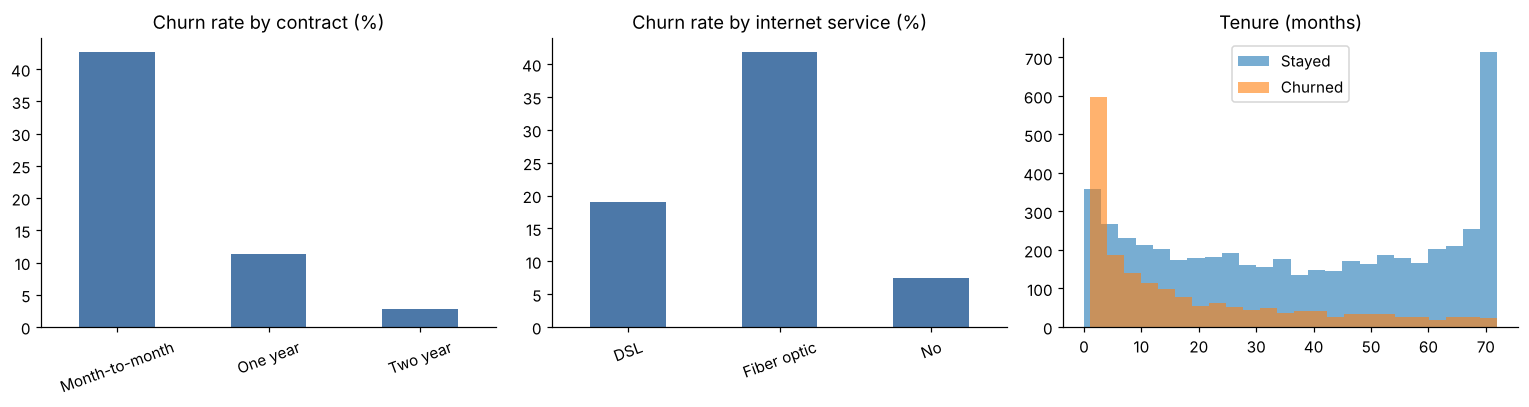

PaymentMethod
Electronic check             45.3
Mailed check                 19.1
Bank transfer (automatic)    16.7
Credit card (automatic)      15.2
Name: Churn, dtype: float64


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
df.groupby("Contract").Churn.mean().mul(100).plot.bar(ax=ax[0], color="#4c78a8"); ax[0].set_title("Churn rate by contract (%)"); ax[0].set_xlabel("")
df.groupby("InternetService").Churn.mean().mul(100).plot.bar(ax=ax[1], color="#4c78a8"); ax[1].set_title("Churn rate by internet service (%)"); ax[1].set_xlabel("")
for lab, g in df.groupby("Churn"): ax[2].hist(g.tenure, bins=24, alpha=.6, label="Churned" if lab else "Stayed")
ax[2].set_title("Tenure (months)"); ax[2].legend()
for a in ax[:2]: a.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.savefig(FIG/"eda_overview.png", bbox_inches="tight"); plt.show()
print(df.groupby("PaymentMethod").Churn.mean().mul(100).round(1).sort_values(ascending=False))

Churn is concentrated among **month-to-month contracts**, **fibre-optic internet**, **new customers** (short tenure) and
**electronic-cheque payers**. These are associations in a single snapshot of data, not proof of cause.

## 3. Train / test split and preprocessing

In [4]:
X, y = df.drop(columns="Churn"), df["Churn"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(X_train.shape, X_test.shape, "| churn rate train/test: %.3f / %.3f" % (y_train.mean(), y_test.mean()))

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in X.columns if c not in num_cols]
pre = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

(5634, 19) (1409, 19) | churn rate train/test: 0.265 / 0.265


The test set is set aside now and used **once**, at the end. All model choices are made with cross-validation on the training set.

## 4. Baseline and model comparison (5-fold stratified cross-validation)

In [5]:
models = {
    "Majority-class baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": LogisticRegression(max_iter=2000, class_weight="balanced", C=0.5),
    "Random forest": RandomForestClassifier(n_estimators=400, min_samples_leaf=5, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
    "Gradient boosting": HistGradientBoostingClassifier(learning_rate=0.05, max_depth=3, max_iter=250, random_state=SEED),
}
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
rows = []
for name, est in models.items():
    pipe = Pipeline([("pre", pre), ("model", est)])
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["roc_auc", "average_precision", "recall", "f1"], n_jobs=1)
    rows.append({"model": name, "ROC-AUC": r["test_roc_auc"].mean(), "PR-AUC": r["test_average_precision"].mean(),
                 "recall": r["test_recall"].mean(), "F1": r["test_f1"].mean(), "ROC-AUC sd": r["test_roc_auc"].std()})
cv_table = pd.DataFrame(rows).set_index("model").round(3)
cv_table

,ROC-AUC,PR-AUC,recall,F1,ROC-AUC sd
model,,,,,
Majority-class baseline,0.500,0.265,0.000,0.000,0.000
Logistic regression,0.846,0.660,0.801,0.628,0.012
Random forest,0.846,0.655,0.728,0.631,0.009
Gradient boosting,0.847,0.668,0.522,0.585,0.011


ROC-AUC and PR-AUC are used for model selection because they do not depend on a particular decision threshold. The majority-class
baseline has a ROC-AUC of 0.5 by construction and gives the number every real model has to beat.

## 5. Final model on the held-out test set

In [6]:
best_name = cv_table["ROC-AUC"].drop("Majority-class baseline").idxmax()
print("Selected by cross-validated ROC-AUC:", best_name)
final = Pipeline([("pre", pre), ("model", models[best_name])]).fit(X_train, y_train)
proba = final.predict_proba(X_test)[:, 1]
base = Pipeline([("pre", pre), ("model", models["Majority-class baseline"])]).fit(X_train, y_train)

def summarise(p, thr):
    pred = (p >= thr).astype(int)
    return {"threshold": thr, "precision": precision_score(y_test, pred), "recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred)}

print("Test ROC-AUC: %.3f | Test PR-AUC: %.3f (baseline PR-AUC = churn rate = %.3f)" %
      (roc_auc_score(y_test, proba), average_precision_score(y_test, proba), y_test.mean()))
pd.DataFrame([summarise(proba, t) for t in (0.3, 0.4, 0.5)]).round(3)

Selected by cross-validated ROC-AUC: Gradient boosting


Test ROC-AUC: 0.844 | Test PR-AUC: 0.659 (baseline PR-AUC = churn rate = 0.265)


,threshold,precision,recall,F1
0,0.3,0.535,0.767,0.631
1,0.4,0.580,0.647,0.612
2,0.5,0.677,0.532,0.596


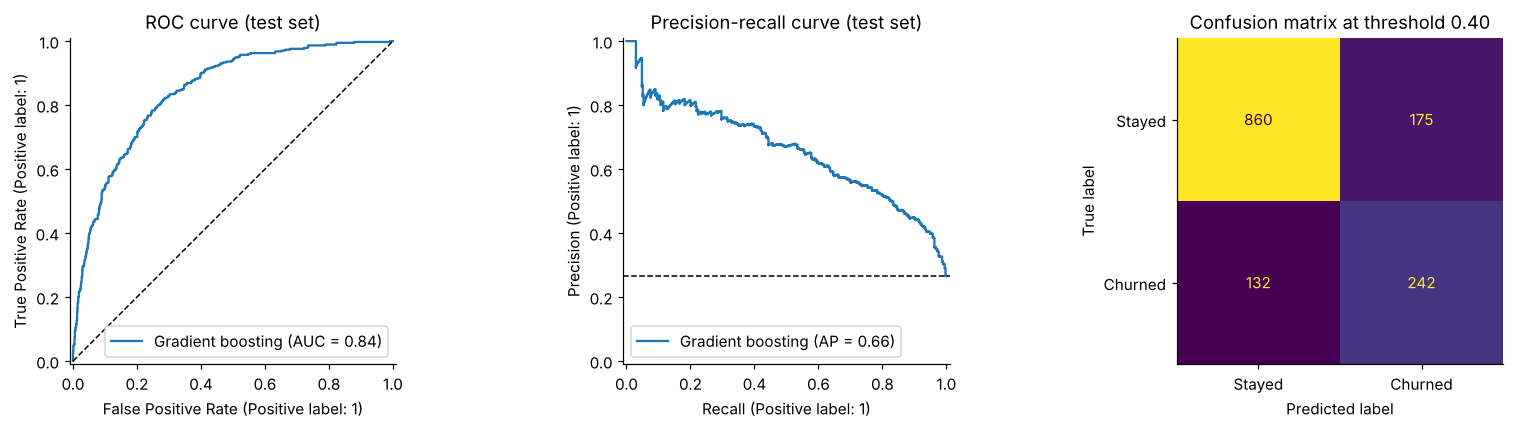

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
RocCurveDisplay.from_predictions(y_test, proba, ax=ax[0], name=best_name); ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].set_title("ROC curve (test set)")
PrecisionRecallDisplay.from_predictions(y_test, proba, ax=ax[1], name=best_name); ax[1].axhline(y_test.mean(), color="k", ls="--", lw=1); ax[1].set_title("Precision-recall curve (test set)")
ConfusionMatrixDisplay.from_predictions(y_test, (proba >= 0.4).astype(int), display_labels=["Stayed", "Churned"], ax=ax[2], colorbar=False); ax[2].set_title("Confusion matrix at threshold 0.40")
plt.tight_layout(); plt.savefig(FIG/"evaluation.png", bbox_inches="tight"); plt.show()

**Choosing a threshold.** Missing a customer who is about to leave (false negative) usually costs more than a wasted retention call
(false positive), so a threshold below 0.5 is reasonable. The 0.40 line above is an illustration; in practice the threshold would
be set from the real cost of a call versus the value of a saved customer.

## 6. What is associated with churn? (permutation importance on the test set)

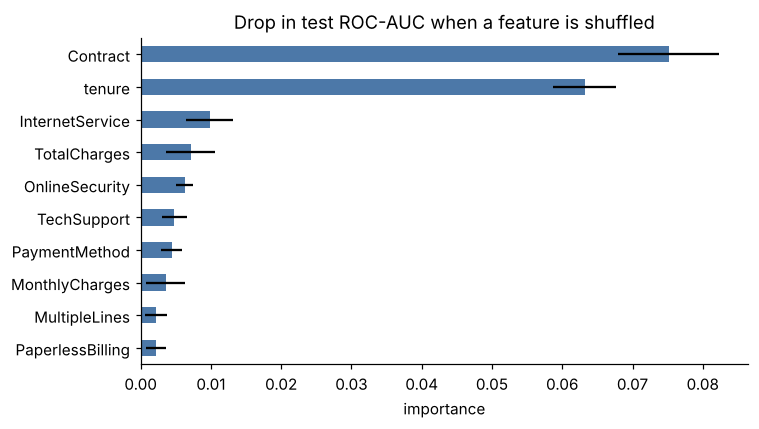

Contract            0.0751
tenure              0.0632
InternetService     0.0098
TotalCharges        0.0071
OnlineSecurity      0.0063
TechSupport         0.0048
PaymentMethod       0.0044
MonthlyCharges      0.0036
MultipleLines       0.0022
PaperlessBilling    0.0022
dtype: float64

In [8]:
perm = permutation_importance(final, X_test, y_test, scoring="roc_auc", n_repeats=15, random_state=SEED, n_jobs=1)
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=True).tail(10)
err = pd.Series(perm.importances_std, index=X_test.columns).loc[imp.index]
ax = imp.plot.barh(xerr=err, figsize=(7, 4), color="#4c78a8")
ax.set_title("Drop in test ROC-AUC when a feature is shuffled"); ax.set_xlabel("importance")
plt.tight_layout(); plt.savefig(FIG/"permutation_importance.png", bbox_inches="tight"); plt.show()
imp.sort_values(ascending=False).round(4)

Permutation importance shows which inputs the model *relies on*; it does not show that changing a feature would change a
customer's behaviour. Features that are correlated (for example tenure and total charges) share their importance, so each can look smaller
than it really is.

## 7. Does the model help a retention team? (lift and value-weighted ranking)

In [9]:
res = pd.DataFrame({"churn": y_test.values, "p": proba, "monthly": X_test["MonthlyCharges"].values})
res["value_at_risk"] = res.p * res.monthly          # expected monthly revenue lost if no action is taken
n = len(res)
rows = []
for frac in (0.1, 0.2, 0.3):
    k = int(frac * n)
    by_risk = res.sort_values("p", ascending=False).head(k)
    by_value = res.sort_values("value_at_risk", ascending=False).head(k)
    rows.append({"contact top": f"{int(frac*100)}%",
                 "churners caught (random)": res.churn.mean() * k,
                 "churners caught (by risk)": by_risk.churn.sum(),
                 "lift vs random": by_risk.churn.mean() / res.churn.mean(),
                 "monthly revenue of churners caught (by risk)": (by_risk.churn * by_risk.monthly).sum(),
                 "monthly revenue of churners caught (by risk x charge)": (by_value.churn * by_value.monthly).sum()})
lift = pd.DataFrame(rows).round(2); lift

,contact top,churners caught (random),churners caught (by risk),lift vs random,monthly revenue of churners caught (by risk),monthly revenue of churners caught (by risk x charge)
0,10%,37.16,109,2.93,8591.00,8838.95
1,20%,74.59,189,2.53,14520.95,15209.50
2,30%,112.01,245,2.19,18597.50,19667.90


Calling customers in order of predicted risk finds far more churners than calling at random (lift above 1). Ranking by
**risk x monthly charge** is a simple way to put the revenue at stake first; the last two columns compare the two orderings on the held-out customers.

## 8. Conclusions and limitations

**What the results show**
- All three real models beat the baseline by a wide margin (cross-validated ROC-AUC about 0.85 against 0.50). The three models are **statistically indistinguishable**: their ROC-AUC values differ by about 0.001 while the fold-to-fold spread is about 0.01. Gradient boosting was selected only because it scored marginally highest, so a simpler model such as logistic regression would serve about as well and is easier to explain.
- On the untouched test set the selected model reaches ROC-AUC 0.84 and PR-AUC 0.66, against a PR-AUC of 0.27 for a model with no skill. The result held up from cross-validation to test, which suggests the model selection did not overfit.
- Contract type and tenure are the features the model relies on most, in line with the exploratory charts: month-to-month, newer customers churn most.
- Contacting the top 20% of customers by predicted risk would reach about 2.5 times as many churners as contacting 20% at random. Ranking by risk x monthly charge catches slightly more monthly revenue than ranking by risk alone.

**Limitations**
- The data is one snapshot of a fictional operator with no dates. It cannot show *when* customers leave or whether a past offer worked, so the model predicts risk, not the effect of a retention action.
- Importance scores describe association, not cause. Switching a customer to a longer contract does not necessarily stop them leaving.
- The dataset contains 22 rows that are identical once the customer ID is removed. They were kept because they may be genuinely different customers with the same profile.
- The threshold and the "value at risk" calculation use simple assumptions. A real project would use actual call costs, offer costs and customer lifetime value.
- The sample is small and from a single source, so the performance figures should not be assumed to carry over to a real telecom operator.

**Possible next steps:** calibrate the predicted probabilities, add a customer-segmentation step (clustering) so offers can be tailored, and test a cost-based threshold.

---
*Dataset: IBM Telco Customer Churn sample data (public sample dataset, fictional company).*